# NHL Expansion Case Data Analysis

The NHL is expanding, and our job is to decide between three cities:
- Kansas City
- Portland
- Austin

...

We will decide which city to recommend by breaking down the problem into three main areas:
- The market opportunity of each city
- The economic status of each city
- The feasibility of each city

### Let's start by analyzing the market opportunity of the three cities.

We'll do this by comparing them based on relative support for their current MLS teams (Sporting KC, The Timbers, and Austin FC). Since there will be obvious differences between the three based on the popularity of the NFL vs. the MLS, we will try to account for that by comparing attendance to peer teams.

We'll compare ratios of:
- Sporting KC to the average NFL attendance
- The Timbers to the average MLS attendance
- Austin FC to the average MLS attendance

...

Let's start by loading in some datasets


In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [102]:
tax_info = pd.read_csv("tax-dataset-2023.csv").query("STATE == 'OR' | STATE == 'TX' | STATE == 'KS' | STATE == 'MO'").rename(columns={"A02650": "Total Income Amount"})
tax_info.head()

,STATEFIPS,STATE,zipcode,agi_stub,N1,mars1,MARS2,MARS4,ELF,CPREP,...,N85300,A85300,N11901,A11901,N11900,A11900,N11902,A11902,N12000,A12000
49504,20,KS,0,1,339710.0,253620.0,36630.0,39320.0,317430.0,9700.0,...,0.0,0.0,35500.0,29861.0,252830.0,462614.0,251530.0,460560.0,1300.0,2054.0
49505,20,KS,0,2,317270.0,188080.0,57110.0,59710.0,301870.0,6600.0,...,0.0,0.0,67730.0,81276.0,247590.0,655728.0,244500.0,649099.0,3090.0,6629.0
49506,20,KS,0,3,217970.0,106550.0,72120.0,28800.0,206750.0,4470.0,...,0.0,0.0,61640.0,124806.0,159510.0,391090.0,154920.0,379882.0,4590.0,11208.0
49507,20,KS,0,4,137800.0,43670.0,75150.0,10520.0,129560.0,1840.0,...,0.0,0.0,46390.0,124030.0,88170.0,269349.0,85370.0,259595.0,2800.0,9754.0
49508,20,KS,0,5,244510.0,34670.0,194950.0,7690.0,233020.0,4280.0,...,80.0,53.0,98960.0,473785.0,144990.0,605631.0,133700.0,528284.0,11290.0,77347.0


In [103]:
mls_attendance = pd.read_csv("mls_2025_attendance.csv").drop(columns={"Source Page"})
mls_attendance.head()

,Rank,Stadium,Club,Capacity,Spectators,Average,Matches,Sold Out,Capacity Utilization (%)
0,1,Mercedes-Benz Stadium,Atlanta United FC,73019,651192,38305,17,0,52.5
1,2,Lumen Field,Seattle Sounders FC,68740,542904,31936,17,0,46.5
2,3,Bank of America Stadium,Charlotte FC,75412,472174,27775,17,0,36.8
3,4,Nu Stadium,Inter Miami CF,26700,444421,26142,17,1,97.9
4,5,Soldier Field,Chicago Fire FC,61500,438911,25818,17,1,42.0


In [104]:
nfl_attendance = pd.read_csv("nfl_2025_attendance.csv")
nfl_attendance.head()

,Rank,Team,Home GMS,Home Total,Home Avg,Road GMS,Road Total,Road Avg,Overall GMS,Overall Total,Overall Avg
0,1,Dallas,8,743934,92991,9,622957,69217,17,1366891,80405
1,2,Denver,9,677305,75256,8,534801,66850,17,1212106,71300
2,3,Kansas City,9,661146,73460,8,561852,70231,17,1222998,71941
3,4,NY Jets,9,660246,73360,8,530705,66338,17,1190951,70055
4,5,NY Giants,8,638295,79786,9,622771,69196,17,1261066,74180


Let's extract some numbers we can actually use. We're going to get the average attendance of home games for the teams from each of our three candidate cities, and also the league wide average attendance for both leagues.

In [106]:
# getting attendance numbers for MLS teams
portland_attendance = mls_attendance.query("Club == 'Portland Timbers'")['Average'].iloc[0]
austin_attendance = mls_attendance.query("Club == 'Austin FC'")['Average'].iloc[0]
kc_attendance = mls_attendance.query("Club == 'Sporting Kansas City'")['Average'].iloc[0]
mls_avg = mls_attendance['Average'].mean()

Now let's get the ratios of each team's attendance compared to the average.

In [107]:
portland_attendance_ratio = portland_attendance/mls_avg
austin_attendance_ratio = austin_attendance/mls_avg
kc_attendance_ratio = kc_attendance/nfl_avg

print(f"Portland's ratio is: {portland_attendance_ratio}")
print(f"Austin's ratio is: {austin_attendance_ratio}")
print(f"Kansas City's ratio is: {kc_attendance_ratio}")

Portland's ratio is: 1.0196902678318598
Austin's ratio is: 0.9420982257104654
Kansas City's ratio is: 0.22435242768945476


Let's make a bar chart to visualize the differences.

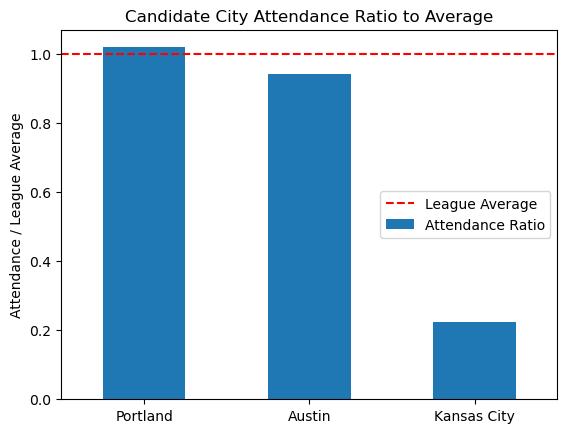

In [108]:
df = pd.DataFrame({
    "City": ["Portland", "Austin", "Kansas City"],
    "Attendance Ratio": [portland_attendance_ratio,austin_attendance_ratio,kc_attendance_ratio]
})

ax = df.plot.bar(x='City', rot=0, xlabel="", ylabel = "Attendance / League Average", title='Candidate City Attendance Ratio to Average', legend=None)
ax.axhline(y=1, linestyle='--', color='red', label = 'League Average')
ax.legend()

Looks like either Portland or Austin are pretty viable, with relatively average attendances, and Kansas City is significantly below.

...

### Let's investigate the economics of each area

The goal here is to develop an understanding of how much disposable income locals have. This will help us make a more educated guess on how large the market is in each city.

A secondary goal is to investigate what the status is on corporations in the city that could serve as potential sponsors.

In [109]:
# get kc average income
kc_zips = [
    # Kansas City, MO
    64101, 64102, 64105, 64106, 64108, 64109, 64110, 64111, 64112, 64113,
    64114, 64116, 64117, 64118, 64119, 64120, 64123, 64124, 64125, 64126,
    64127, 64128, 64129, 64130, 64131, 64132, 64133, 64134, 64136, 64137,
    64138, 64139, 64145, 64146, 64147, 64149, 64151, 64152, 64153, 64154,
    64155, 64156, 64157, 64158, 64161, 64163, 64164, 64165, 64166, 64167,
    # Kansas City, KS
    66101, 66102, 66103, 66104, 66105, 66106, 66109, 66111, 66112, 66115,
    66118,
]
kc_tax = tax_info.query("STATE in ['MO', 'KS'] and zipcode in @kc_zips")
kc_income = kc_tax['Total Income Amount'].median()

#get austin average income
austin_zips = [
    78701, 78702, 78703, 78704, 78705, 78712, 78717, 78719, 78721, 78722,
    78723, 78724, 78725, 78726, 78727, 78728, 78729, 78730, 78731, 78732,
    78733, 78734, 78735, 78736, 78737, 78738, 78739, 78741, 78742, 78744,
    78745, 78746, 78747, 78748, 78749, 78750, 78751, 78752, 78753, 78754,
    78756, 78757, 78758, 78759,
]
austin_tax = tax_info.query("STATE == 'TX' and zipcode in @austin_zips")
austin_income = austin_tax['Total Income Amount'].median()

portland_zips = [
    97201, 97202, 97203, 97204, 97205, 97206, 97209, 97210, 97211, 97212,
    97213, 97214, 97215, 97216, 97217, 97218, 97219, 97220, 97221, 97227,
    97230, 97231, 97232, 97233, 97236, 97239, 97266,
]
portland_tax = tax_info.query("STATE == 'OR' and zipcode in @portland_zips")
portland_income = portland_tax['Total Income Amount'].median()

print(f"Portland's average income is: {portland_income}")
print(f"Austin's average income is: {austin_income}")
print(f"Kansas City's average income is: {kc_income}")

Portland's average income is: 131285.0
Austin's average income is: 104624.5
Kansas City's average income is: 36410.5


Let's create another bar chart to visualize the differences.

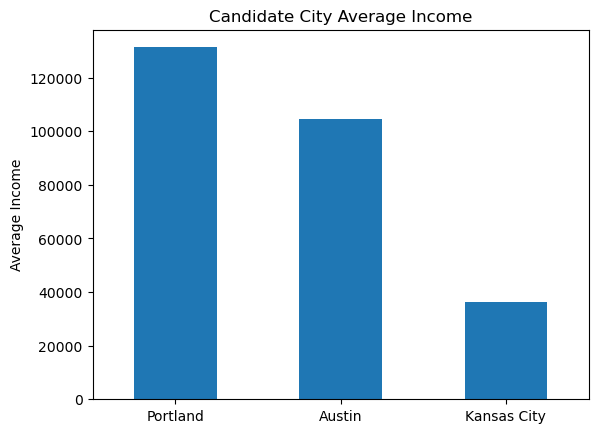

In [110]:
df = pd.DataFrame({
    "City": ["Portland", "Austin", "Kansas City"],
    "Average Income": [portland_income,austin_income,kc_income]
})

ax = df.plot.bar(x='City', rot=0, xlabel="", ylabel = "Average Income", title='Candidate City Average Income', legend=None)
plt.show()

Now let's look at corporate prospects.